# Friction-Induced Vibration: corrected physics + deep learning

This notebook replaces the original `friction_vibration.ipynb`. It keeps the idea (a 1-DOF
oscillator with velocity-weakening friction, tuned by gradient descent) but fixes the physics
and the optimisation, and adds three deep-learning components.

## What was wrong in the original

| # | Issue in the original | Consequence | Fix here |
|---|---|---|---|
| 1 | Friction written as `+F·sign(v)`, i.e. along the velocity | Friction **injects** energy; the model is non-physical | Friction opposes the **relative** slip velocity |
| 2 | No moving belt / disc | Nothing drives self-excited vibration; it is just a strange damped oscillator | Classic mass-on-moving-belt model, slip velocity `v_r = v_b − ẋ` |
| 3 | Objective = `max(E) − min(E)` of mechanical energy | Not a vibration measure; the Bayesian search ends with `k` and `α` on their bounds | Late-time vibration RMS + a cost on damping (a real design trade-off) |
| 4 | "SGD" = deterministic finite differences (h = 1e-5) on an adaptive `solve_ivp` | Gradients are solver noise, 10²–10⁵ times the true value; the saved output is stuck at 0.659 for 10,000 iterations | Exact gradients by automatic differentiation; *stochastic* minibatches of uncertain operating conditions |
| 5 | `gp_minimize` (Bayesian optimisation) in cells described as SGD | Method mislabelled | Adam with `clip_grad_norm_` |
| 6 | R² computed between a prediction and itself | Always 1.0, meaningless | R² of a surrogate on a held-out test set |
| 7 | `np.sign(v)` discontinuity, unbounded parameters | Solver chatter, non-differentiable, k could go negative | `tanh(v_r/ε)` regularisation, bounded re-parameterisation |

## Model

$$ m\ddot x + c\dot x + kx = N\,\mu(v_r)\tanh\!\left(\tfrac{v_r}{\varepsilon}\right),\qquad v_r = v_b-\dot x,\qquad N = mg $$

$$ \mu(v_r) = \mu_k + (\mu_s-\mu_k)\,e^{-\alpha|v_r|} \quad\text{(exponential velocity-weakening law)} $$

Linearising about steady sliding gives an effective damping $c + N\mu'(v_b)$, so steady sliding is
linearly unstable when

$$ c < c_{crit} = N(\mu_s-\mu_k)\,\alpha\,e^{-\alpha v_b}. $$

This analytic boundary is used below to sanity-check the learned models.

**Runtime:** about 25 minutes on a CPU (Colab works as-is; PyTorch, SciPy and Matplotlib are
pre-installed). A GPU mostly speeds up section 5.

## Deep-learning components

1. **Differentiable simulator** (batched RK4 in PyTorch): exact gradients, so real SGD with gradient clipping works.
2. **Robust design by SGD**: each step samples random belt speeds and friction parameters, which is what makes it *stochastic*.
3. **Neural surrogate + stick-slip classifier**: fast prediction of vibration level and regime; optimisation through the surrogate.
4. **Hybrid neural ODE** (separate script `friction_law_discovery.py`): learns an unknown friction law from noisy vibration measurements.
5. **Fourier Neural Operator**: maps a time-varying belt-speed history to the full vibration response.

In [1]:
import time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

torch.set_default_dtype(torch.float64)
torch.manual_seed(0)
np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

M, G = 1.0, 9.81
N_LOAD = M * G          # normal load (N)
EPS = 0.02              # tanh regularisation of sign(v_r) (m/s)
DT = 4e-3               # RK4 step (s); accuracy checked against Radau below (and at the corners of the parameter box)
T_END = 20.0            # simulation length (s)
WIN = 0.4               # last 40% of the record = "steady state"


def mu_exp(vr, mu_s, mu_k, alpha):
    """Exponential velocity-weakening friction coefficient."""
    return mu_k + (mu_s - mu_k) * torch.exp(-alpha * vr.abs())


def make_rhs(friction):
    """friction(vr, p) -> friction force on the mass. Returns the state derivative function."""
    def rhs(x, v, p):
        vr = p["vb"] - v
        a = (friction(vr, p) - p["c"] * v - p["k"] * x) / M
        return v, a
    return rhs


def exp_friction(vr, p):
    return N_LOAD * mu_exp(vr, p["mu_s"], p["mu_k"], p["alpha"]) * torch.tanh(vr / EPS)


rhs_exp = make_rhs(exp_friction)


def simulate(rhs, p, T=T_END, dt=DT, x0=None, v0=None, save_every=5):
    """Batched fixed-step RK4. Every entry of p is a tensor broadcastable to the batch shape.
    Fully differentiable with respect to anything in p. Returns t, X, V with shape [n_t, batch]."""
    shape = torch.broadcast_tensors(*p.values())[0].shape
    x = torch.zeros(shape) if x0 is None else x0
    v = torch.zeros(shape) if v0 is None else v0
    n = int(round(T / dt))
    xs, vs = [x], [v]
    for i in range(1, n + 1):
        k1x, k1v = rhs(x, v, p)
        k2x, k2v = rhs(x + 0.5 * dt * k1x, v + 0.5 * dt * k1v, p)
        k3x, k3v = rhs(x + 0.5 * dt * k2x, v + 0.5 * dt * k2v, p)
        k4x, k4v = rhs(x + dt * k3x, v + dt * k3v, p)
        x = x + dt / 6 * (k1x + 2 * k2x + 2 * k3x + k4x)
        v = v + dt / 6 * (k1v + 2 * k2v + 2 * k3v + k4v)
        if i % save_every == 0:
            xs.append(x)
            vs.append(v)
    t = torch.arange(len(xs)) * dt * save_every
    return t, torch.stack(xs), torch.stack(vs)


def vib_rms(V):
    """Steady-state vibration level: std of the mass velocity over the last WIN of the record."""
    n0 = int(V.shape[0] * (1 - WIN))
    return V[n0:].std(dim=0)


def c_crit(vb, mu_s, mu_k, alpha):
    return N_LOAD * (mu_s - mu_k) * alpha * np.exp(-alpha * vb)

### Check the integrator against SciPy
The same smoothed ODE is solved with a tight-tolerance implicit solver (`Radau`). If fixed-step RK4
agrees, the simulator can be trusted for the gradient work below.

max relative displacement error, RK4 vs Radau: 1.08e-05
c = 0.3, analytic c_crit = 2.204 -> steady sliding should be unstable (stick-slip)


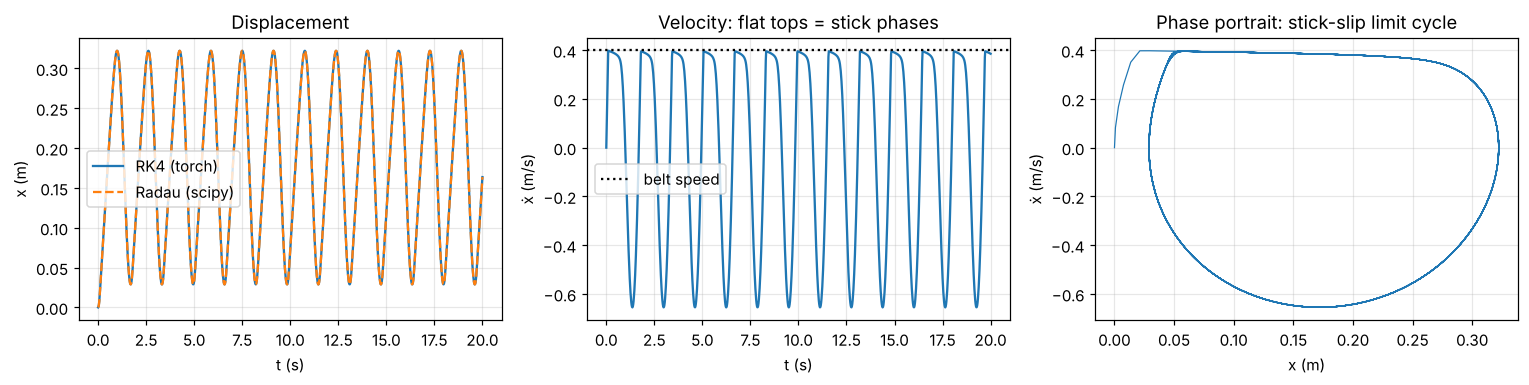

In [2]:
p_demo = dict(c=torch.tensor(0.3), k=torch.tensor(20.0), vb=torch.tensor(0.4),
              mu_s=torch.tensor(0.55), mu_k=torch.tensor(0.30), alpha=torch.tensor(2.0))
t, X, V = simulate(rhs_exp, p_demo)

pd = {k: float(v) for k, v in p_demo.items()}
def ode_np(_, y):
    x, v = y
    vr = pd["vb"] - v
    mu = pd["mu_k"] + (pd["mu_s"] - pd["mu_k"]) * np.exp(-pd["alpha"] * abs(vr))
    return [v, (N_LOAD * mu * np.tanh(vr / EPS) - pd["c"] * v - pd["k"] * x) / M]

ref = solve_ivp(ode_np, (0, T_END), [0, 0], method="Radau", t_eval=t.numpy(), rtol=1e-9, atol=1e-11)
err = np.max(np.abs(ref.y[0] - X.numpy())) / np.max(np.abs(ref.y[0]))
print(f"max relative displacement error, RK4 vs Radau: {err:.2e}")
print(f"c = {pd['c']}, analytic c_crit = {c_crit(pd['vb'], pd['mu_s'], pd['mu_k'], pd['alpha']):.3f}"
      " -> steady sliding should be unstable (stick-slip)")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(t, X, label="RK4 (torch)")
ax[0].plot(t, ref.y[0], "--", label="Radau (scipy)")
ax[0].set(xlabel="t (s)", ylabel="x (m)", title="Displacement")
ax[0].legend()
ax[1].plot(t, V)
ax[1].axhline(pd["vb"], color="k", ls=":", label="belt speed")
ax[1].set(xlabel="t (s)", ylabel="ẋ (m/s)", title="Velocity: flat tops = stick phases")
ax[1].legend()
ax[2].plot(X, V, lw=0.8)
ax[2].set(xlabel="x (m)", ylabel="ẋ (m/s)", title="Phase portrait: stick-slip limit cycle")
plt.tight_layout()
plt.savefig("fig1_validation.png")
plt.show()

## 2. Robust design of the damping by stochastic gradient descent

**Design variable:** damping `c ∈ [0.05, 4]` N·s/m. Stiffness is fixed at `k = 20` N/m. An
earlier version also optimised `k`, but the objective is flat in `k` (checked at the end of this
section): the linear stability limit `c_crit` does not contain `k`, and neither does the
velocity amplitude of the stick-slip cycle to first order.

**Uncertain operating conditions,** sampled fresh at every step: belt speed `v_b ~ U(0.3, 1.0)`,
`α ~ U(1, 2)`, `μ_s ~ U(0.45, 0.55)`, `μ_k ~ U(0.28, 0.32)`.

**Objective:** expected late-time vibration plus a cost on damping (without the cost the optimum
is simply "maximum damping"):

$$ J(c) = \mathbb{E}_{\text{conditions}}\big[\,\text{RMS}(\dot x)\ \text{over}\ 12\text{–}20\ \text{s}\,\big] + \lambda\,c,\qquad \lambda = 0.05 $$

The RMS window starts 12 s after the system is released from rest, so slow transients near the
stability boundary still count. Section 2's check separates those from *sustained* stick-slip
using 200 s runs.

Each step samples new random conditions, so each gradient is a noisy, unbiased estimate of
`dJ/dc`; this is what makes it stochastic gradient descent (the Adam variant). Gradient
clipping (`clip_grad_norm_`, threshold 1) is kept as a safeguard: gradients back-propagated
through 5,000 steps of an unstable system can spike. In this run it rarely activates (see the
gradient-norm plot).

In [3]:
C_LO, C_HI, K_FIX = 0.05, 4.0, 20.0
LAM = 0.05


def sample_conditions(B, gen=None):
    r = lambda lo, hi: lo + (hi - lo) * torch.rand(B, generator=gen)
    return dict(vb=r(0.3, 1.0), alpha=r(1.0, 2.0), mu_s=r(0.45, 0.55), mu_k=r(0.28, 0.32))


def c_from_theta(theta):
    """Unconstrained theta -> bounded c via a sigmoid map."""
    return C_LO + (C_HI - C_LO) * torch.sigmoid(theta)


def true_objective(c, cond, k=K_FIX, T=T_END):
    _, _, V = simulate(rhs_exp, dict(c=c, k=torch.tensor(k), **cond), T=T)
    return vib_rms(V).mean() + LAM * c


theta = torch.tensor(-1.5, requires_grad=True)   # start: c = 0.77 N·s/m (deep in stick-slip)
opt = torch.optim.Adam([theta], lr=0.08)
hist = []
t0 = time.time()
for it in range(80):
    c = c_from_theta(theta)
    J = true_objective(c, sample_conditions(24))
    opt.zero_grad()
    J.backward()
    gnorm = torch.nn.utils.clip_grad_norm_([theta], max_norm=1.0)   # gradient clipping
    opt.step()
    hist.append((it, J.item(), c.item(), gnorm.item()))
    if it % 10 == 0 or it == 79:
        print(f"it {it:3d}  J={J.item():.4f}  c={c.item():.3f}  |grad| before clip={gnorm.item():.3g}")
print(f"time: {time.time() - t0:.0f} s")

c_sgd = float(c_from_theta(theta.detach()))
c_start = float(c_from_theta(torch.tensor(-1.5)))
H = np.array(hist)

it   0  J=0.5181  c=0.771  |grad| before clip=0.321


it  10  J=0.2271  c=1.332  |grad| before clip=0.399


it  20  J=0.1377  c=1.944  |grad| before clip=0.0135


it  30  J=0.1143  c=2.273  |grad| before clip=0.0443


it  40  J=0.1281  c=2.350  |grad| before clip=0.0478


it  50  J=0.1306  c=2.297  |grad| before clip=0.0517


it  60  J=0.1147  c=2.230  |grad| before clip=0.0245


it  70  J=0.1199  c=2.141  |grad| before clip=0.0561


it  79  J=0.1060  c=2.099  |grad| before clip=0.0423
time: 495 s


### Check the SGD design
The start design and the optimised design are evaluated on 400 fresh random operating conditions
the optimiser never saw. Two measures are reported: the late-time RMS used in `J` (20 s run), and
whether stick-slip is still present after 200 s (*sustained*). The analytic linear-stability limit
is shown for comparison; its worst case over the uncertainty box is at `v_b = 0.3`, `α = 2`,
`μ_s − μ_k = 0.27`.

start        c=0.771 | mean RMS(ẋ)=0.4492 | J=0.4877 | RMS>0.01 at 12–20 s in 100.0% | sustained after 200 s in 93.3% | c<c_crit in 80.5%
SGD optimum  c=2.094 | mean RMS(ẋ)=0.0132 | J=0.1179 | RMS>0.01 at 12–20 s in 13.2% | sustained after 200 s in 3.0% | c<c_crit in 2.8%
analytic c_crit over test conditions: max 2.372, 95th pct 1.939, worst case of the box 2.907


J at the SGD optimum for different k: k=10: 0.1184, k=20: 0.1179, k=30: 0.1178, k=50: 0.1177


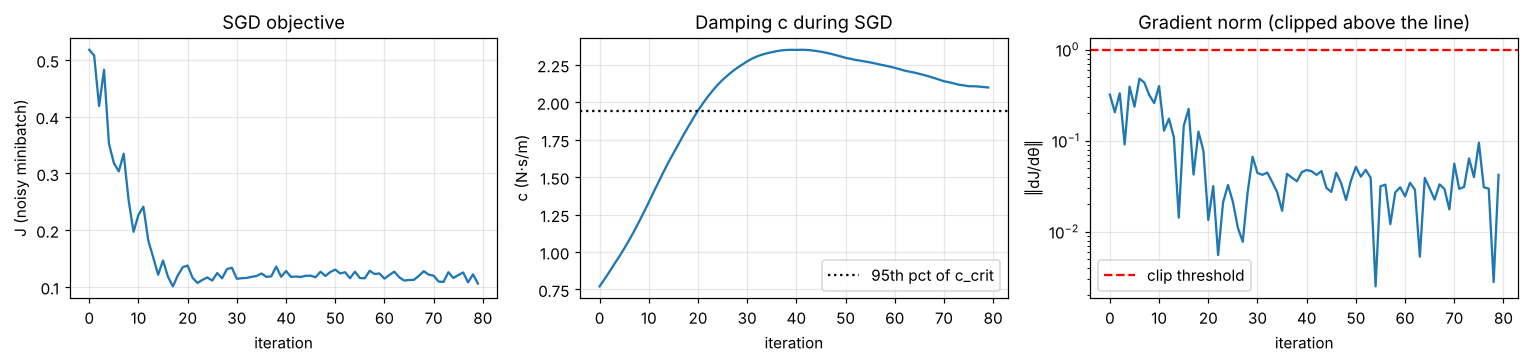

In [4]:
gen = torch.Generator().manual_seed(123)
cond_test = sample_conditions(400, gen)
cc = c_crit(cond_test["vb"].numpy(), cond_test["mu_s"].numpy(), cond_test["mu_k"].numpy(), cond_test["alpha"].numpy())


def evaluate_design(c, k=K_FIX):
    with torch.no_grad():
        _, _, V = simulate(rhs_exp, dict(c=torch.tensor(c), k=torch.tensor(k), **cond_test))
        _, _, VL = simulate(rhs_exp, dict(c=torch.tensor(c), k=torch.tensor(k), **cond_test), T=200.0)
    r, rl = vib_rms(V), vib_rms(VL)
    return dict(J=float(r.mean() + LAM * c), rms=float(r.mean()), late=float((r > 0.01).float().mean()),
                sustained=float((rl > 0.01).float().mean()), lin_unstable=float((c < cc).mean()))


design_rows = {"start": evaluate_design(c_start), "SGD optimum": evaluate_design(c_sgd)}
for name, d in design_rows.items():
    c = c_start if name == "start" else c_sgd
    print(f"{name:12s} c={c:.3f} | mean RMS(ẋ)={d['rms']:.4f} | J={d['J']:.4f} | RMS>0.01 at 12–20 s in {d['late'] * 100:.1f}% "
          f"| sustained after 200 s in {d['sustained'] * 100:.1f}% | c<c_crit in {d['lin_unstable'] * 100:.1f}%")
print(f"analytic c_crit over test conditions: max {cc.max():.3f}, 95th pct {np.percentile(cc, 95):.3f}, "
      f"worst case of the box {c_crit(0.3, 0.55, 0.28, 2.0):.3f}")

# sensitivity of J to k at the optimum (justifies fixing k)
with torch.no_grad():
    Jk = {k: float(true_objective(torch.tensor(c_sgd), cond_test, k=k)) for k in (10.0, 20.0, 30.0, 50.0)}
print("J at the SGD optimum for different k: " + ", ".join(f"k={k:.0f}: {v:.4f}" for k, v in Jk.items()))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
ax[0].plot(H[:, 0], H[:, 1]); ax[0].set(xlabel="iteration", ylabel="J (noisy minibatch)", title="SGD objective")
ax[1].plot(H[:, 0], H[:, 2]); ax[1].axhline(np.percentile(cc, 95), ls=":", c="k", label="95th pct of c_crit")
ax[1].set(xlabel="iteration", ylabel="c (N·s/m)", title="Damping c during SGD"); ax[1].legend()
ax[2].semilogy(H[:, 0], H[:, 3]); ax[2].axhline(1.0, c="r", ls="--", label="clip threshold")
ax[2].set(xlabel="iteration", ylabel="‖dJ/dθ‖", title="Gradient norm (clipped above the line)"); ax[2].legend()
plt.tight_layout(); plt.savefig("fig2_sgd.png"); plt.show()

## 3. Neural surrogate + stick-slip classifier (MLP)

The inputs are six scalars `(c, k, v_b, α, μ_s, μ_k)`, so a multilayer perceptron is the right
architecture; a neural operator would add nothing here (section 5 shows where one does help).
Training data come from the batched simulator: 8,000 random designs and conditions.

The network has two heads:
* **Regression:** `log10(RMS(ẋ) + 1e-4)` over 12–20 s after release, the measure used in `J`.
* **Classification:** *sustained* stick-slip, judged from a 200 s run (`RMS(ẋ) > 0.01 m/s` over
  120–200 s). Near the stability boundary transients decay slowly; shorter records would label
  them as stick-slip. The test set is re-simulated for 400 s to check that the labels are settled.

The classifier is compared with the linear stability rule `c < c_crit`. Friction oscillators can
be *bistable*: steady sliding is linearly stable, yet a large disturbance (here, release from
rest) lands on a stick-slip limit cycle. Cases that vibrate although `c > c_crit` are therefore
re-run from just next to steady sliding: if they then settle, two stable states coexist.

dataset generated in 66.3 s
sustained stick-slip in 32.5% of samples


TEST (1000 unseen samples)
  R² of log10 vibration level : 0.9989
  R² of RMS(ẋ) in m/s         : 0.9858
  classifier accuracy         : 99.2%
  linear-stability rule acc.  : 97.1%


  labels that change between 200 s and 400 s runs: 2 of 1000


  sustained stick-slip although c > c_crit: 29 of 344 vibrating cases; 29 of them settle to steady sliding when released next to it -> confirmed bistable


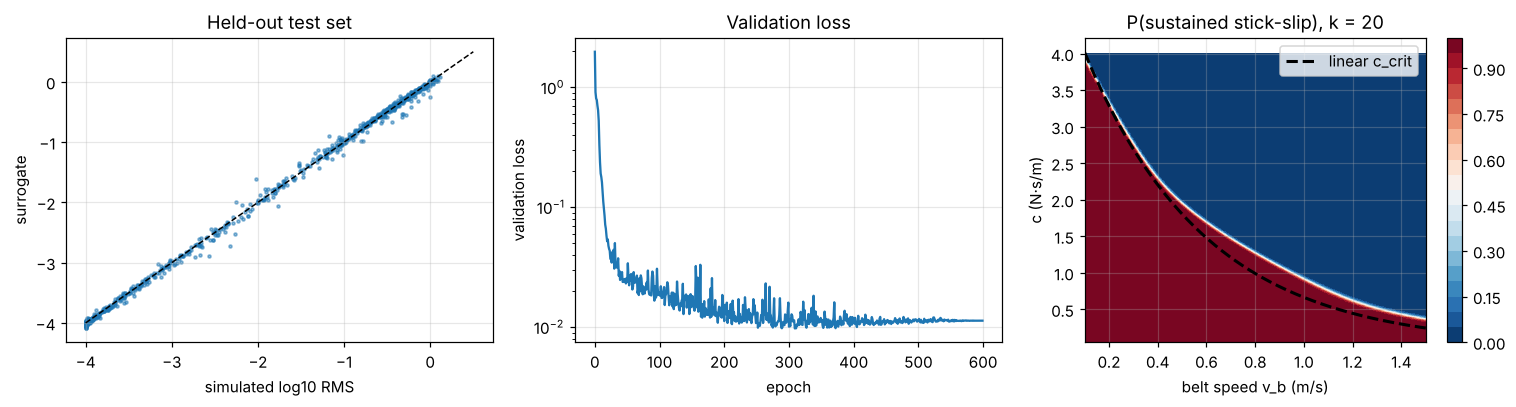

In [5]:
LO = torch.tensor([0.05, 5.0, 0.1, 0.5, 0.40, 0.20])   # c, k, vb, alpha, mu_s, mu_k
HI = torch.tensor([4.00, 50.0, 1.5, 3.0, 0.65, 0.35])
NAMES = ["c", "k", "vb", "alpha", "mu_s", "mu_k"]


def run_batch(P, T=T_END, x0=None):
    p = {n: P[:, i] for i, n in enumerate(NAMES)}
    with torch.no_grad():
        _, _, V = simulate(rhs_exp, p, T=T, x0=x0)
    return vib_rms(V)


t0 = time.time()
gen = torch.Generator().manual_seed(7)
P_all = LO + (HI - LO) * torch.rand(8000, 6, generator=gen)
R_all = torch.cat([run_batch(P_all[i:i + 2000]) for i in range(0, 8000, 2000)])
R_long = torch.cat([run_batch(P_all[i:i + 2000], T=200.0) for i in range(0, 8000, 2000)])
print(f"dataset generated in {time.time() - t0:.1f} s")

Xn = (P_all - LO) / (HI - LO)                      # inputs scaled to [0, 1]
y_reg = torch.log10(R_all + 1e-4)
y_cls = (R_long > 0.01).double()
idx = torch.randperm(8000, generator=gen)
tr, va, te = idx[:6000], idx[6000:7000], idx[7000:]
print(f"sustained stick-slip in {y_cls.mean() * 100:.1f}% of samples")


class Surrogate(nn.Module):
    def __init__(self, w=128):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(6, w), nn.SiLU(), nn.Linear(w, w), nn.SiLU(),
                                  nn.Linear(w, w), nn.SiLU())
        self.reg = nn.Linear(w, 1)
        self.cls = nn.Linear(w, 1)

    def forward(self, x):
        h = self.body(x)
        return self.reg(h).squeeze(-1), self.cls(h).squeeze(-1)


torch.manual_seed(0)
net = Surrogate()
opt = torch.optim.AdamW(net.parameters(), lr=2e-3, weight_decay=1e-5)
EPOCHS = 600
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS)
bce = nn.BCEWithLogitsLoss()
best, best_state, log = 1e9, None, []
for ep in range(EPOCHS):
    net.train()
    for b in torch.randperm(len(tr)).split(256):
        i = tr[b]
        pr, pc = net(Xn[i])
        loss = ((pr - y_reg[i]) ** 2).mean() + 0.3 * bce(pc, y_cls[i])
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(net.parameters(), 1.0)
        opt.step()
    sched.step()
    net.eval()
    with torch.no_grad():
        pr, pc = net(Xn[va])
        vl = ((pr - y_reg[va]) ** 2).mean().item() + 0.3 * bce(pc, y_cls[va]).item()
    log.append(vl)
    if vl < best:
        best, best_state = vl, {k: v.clone() for k, v in net.state_dict().items()}
net.load_state_dict(best_state)


def r2(y, yhat):
    return 1 - ((y - yhat) ** 2).sum() / ((y - y.mean()) ** 2).sum()


with torch.no_grad():
    pr, pc = net(Xn[te])
P_te = P_all[te].numpy()
lin_pred = P_te[:, 0] < c_crit(P_te[:, 2], P_te[:, 4], P_te[:, 5], P_te[:, 3])
true_lab = y_cls[te].numpy().astype(bool)
print(f"TEST (1000 unseen samples)")
print(f"  R² of log10 vibration level : {r2(y_reg[te], pr).item():.4f}")
print(f"  R² of RMS(ẋ) in m/s         : {r2(R_all[te], 10 ** pr - 1e-4).item():.4f}")
print(f"  classifier accuracy         : {((pc > 0).numpy() == true_lab).mean() * 100:.1f}%")
print(f"  linear-stability rule acc.  : {(lin_pred == true_lab).mean() * 100:.1f}%")

# are the 200 s labels settled?  and are the 'vibrating although linearly stable' cases bistable?
R400 = run_batch(P_all[te], T=400.0)
lab400 = (R400 > 0.01).numpy()
print(f"  labels that change between 200 s and 400 s runs: {(lab400 != true_lab).sum()} of 1000")
cand = np.where(true_lab & ~lin_pred)[0]
Pc = P_all[te][cand]
x_eq = N_LOAD * mu_exp(Pc[:, 2], Pc[:, 4], Pc[:, 5], Pc[:, 3]) * torch.tanh(Pc[:, 2] / EPS) / Pc[:, 1]
R_near = run_batch(Pc, T=200.0, x0=x_eq + 1e-3)                  # released next to steady sliding
n_bis = int((R_near < 0.01).sum())
print(f"  sustained stick-slip although c > c_crit: {len(cand)} of {true_lab.sum()} vibrating cases; "
      f"{n_bis} of them settle to steady sliding when released next to it -> confirmed bistable")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].scatter(y_reg[te], pr, s=4, alpha=0.5)
ax[0].plot([-4, 0.5], [-4, 0.5], "k--", lw=1)
ax[0].set(xlabel="simulated log10 RMS", ylabel="surrogate", title="Held-out test set")
ax[1].semilogy(log); ax[1].set(xlabel="epoch", ylabel="validation loss", title="Validation loss")
# regime map in (vb, c) for nominal friction, k = K_FIX
vb_g, c_g = torch.meshgrid(torch.linspace(0.1, 1.5, 120), torch.linspace(0.05, 4, 120), indexing="xy")
Pg = torch.stack([c_g.flatten(), torch.full((14400,), K_FIX), vb_g.flatten(), torch.full((14400,), 2.0),
                  torch.full((14400,), 0.55), torch.full((14400,), 0.30)], 1)
with torch.no_grad():
    _, pcg = net((Pg - LO) / (HI - LO))
prob = torch.sigmoid(pcg).reshape(120, 120)
cs = ax[2].contourf(vb_g, c_g, prob, levels=20, cmap="RdBu_r")
vbl = np.linspace(0.1, 1.5, 200)
ax[2].plot(vbl, c_crit(vbl, 0.55, 0.30, 2.0), "k--", lw=2, label="linear c_crit")
ax[2].set(xlabel="belt speed v_b (m/s)", ylabel="c (N·s/m)", title="P(sustained stick-slip), k = 20")
ax[2].legend(loc="upper right"); plt.colorbar(cs, ax=ax[2])
plt.tight_layout(); plt.savefig("fig3_surrogate.png"); plt.show()

### Robust design through the surrogate
The same objective `J(c)` as section 2, but the surrogate replaces the simulator. Each step now
uses 4,096 sampled conditions and takes milliseconds. The design is then checked with the
**true** simulator on the same 400 unseen conditions as section 2.

In [6]:
for p_ in net.parameters():
    p_.requires_grad_(False)
theta_s = torch.tensor(-1.5, requires_grad=True)
opt_s = torch.optim.Adam([theta_s], lr=0.05)
t0 = time.time()
for it in range(400):
    c = c_from_theta(theta_s)
    cond = sample_conditions(4096)
    P = torch.stack([c.expand(4096), torch.full((4096,), K_FIX), cond["vb"], cond["alpha"], cond["mu_s"], cond["mu_k"]], 1)
    pr, _ = net((P - LO) / (HI - LO))
    J = (10 ** pr - 1e-4).clamp_min(0).mean() + LAM * c
    opt_s.zero_grad(); J.backward()
    nn.utils.clip_grad_norm_([theta_s], 1.0)
    opt_s.step()
c_sur = float(c_from_theta(theta_s.detach()))
print(f"surrogate SGD: 400 steps in {time.time() - t0:.1f} s -> c={c_sur:.3f}")
design_rows["surrogate optimum"] = evaluate_design(c_sur)
for name, c in [("SGD (sec. 2)", c_sgd), ("surrogate", c_sur)]:
    d = design_rows["SGD optimum" if name.startswith("SGD") else "surrogate optimum"]
    print(f"  {name:13s} c={c:.3f} | true-simulator J={d['J']:.4f} | mean RMS(ẋ)={d['rms']:.4f} | "
          f"sustained after 200 s in {d['sustained'] * 100:.1f}% of test conditions")

surrogate SGD: 400 steps in 4.2 s -> c=2.081


  SGD (sec. 2)  c=2.094 | true-simulator J=0.1179 | mean RMS(ẋ)=0.0132 | sustained after 200 s in 3.0% of test conditions
  surrogate     c=2.081 | true-simulator J=0.1180 | mean RMS(ẋ)=0.0140 | sustained after 200 s in 3.5% of test conditions


## 4. Learning the friction law from data

The hybrid neural-ODE friction-law discovery (known mechanics + a neural network for `μ(v_r)`,
trained on vibration records) lives in the standalone script `friction_law_discovery.py`. It has
a proper held-out validation design, an ensemble, a baseline, a demo with a hidden true law and
a reader for real rig data. Run it separately:

```
python friction_law_discovery.py --demo
```

## 5. Neural operator (1D FNO): time-varying belt speed → vibration response

A neural operator learns a map from **a function to a function**. That only pays off when the
input really is a function. Here it is: in a braking event or a variable-speed drive, the
sliding speed changes during the test, so we want

$$ \mathcal{G}:\; \big(v_b(t),\, c\big) \;\mapsto\; \big(x(t),\, \dot x(t)\big),\qquad t\in[0,10]\ \text{s}. $$

A Fourier Neural Operator (FNO) mixes information globally in time through truncated Fourier
layers, so one forward pass predicts the whole 10 s response. For this 1-DOF system the batched
simulator is itself fast, so the FNO is a demonstration of the method; its value grows with
models that are expensive to simulate (multi-DOF brake models, FE contact models).

**Data:** 2,400 random speed profiles (mean speed, random trend such as a braking ramp, and
random harmonics), each with a random damping `c ∈ [0.2, 3]`. Friction is the nominal exponential
law. Responses are stored at 25 Hz (250 points).

operator dataset: 2400 trajectories x 251 points in 2 s


epoch   0  train MSE 1.1828


epoch  30  train MSE 0.0540


epoch  60  train MSE 0.0070


epoch  90  train MSE 0.0041


epoch 120  train MSE 0.0012


epoch 149  train MSE 0.0011
FNO trained in 659 s, 458k parameters


TEST (400 unseen profiles), median relative L2 error (90th percentile in brackets):
  x(t) full signal          : 2.4%  (10.1%)
  x(t) minus its mean       : 6.2%  (25.9%)
  v(t)                      : 6.8%  (27.1%)
R² of vibration RMS(ẋ) over 5–10 s from FNO outputs: 0.987
time for 400 trajectories: FNO 339 ms (float32), batched RK4 simulator 512 ms (float64)


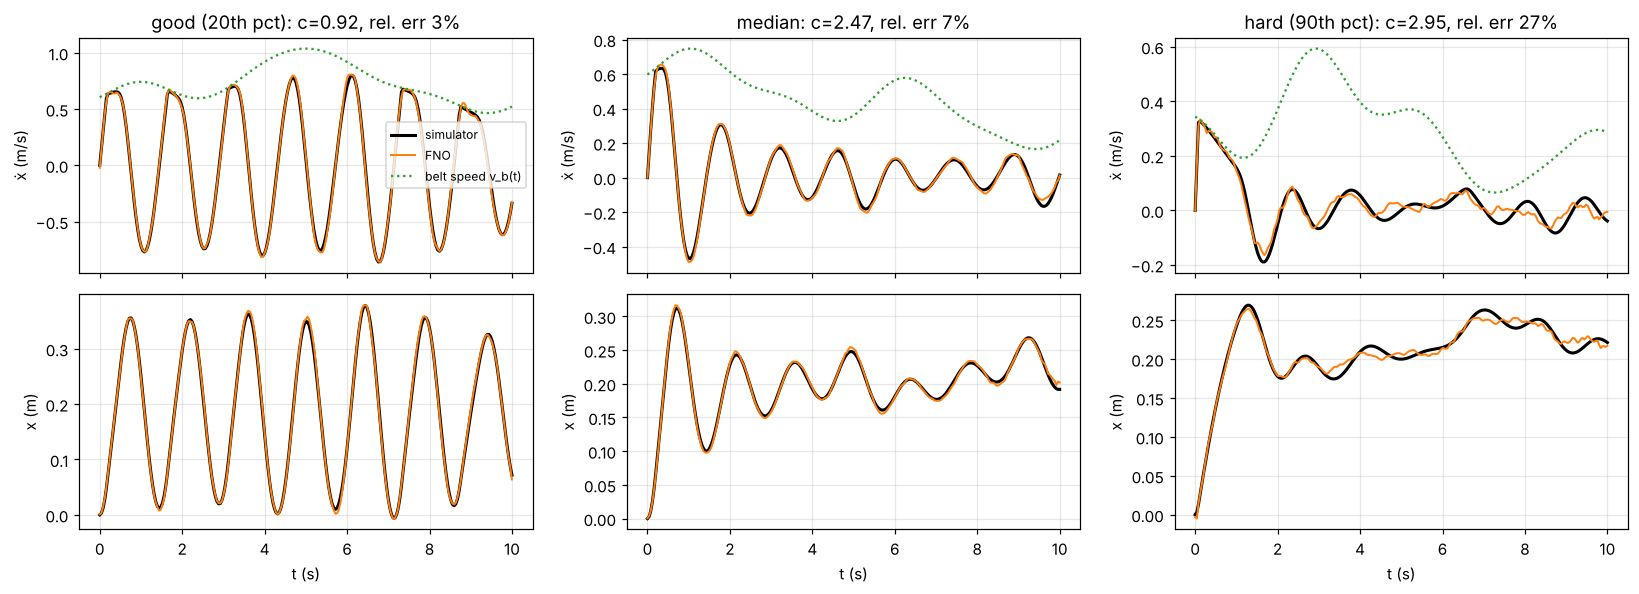

In [7]:
T5, SAVE5 = 10.0, 10                     # 10 s record, keep every 10th RK4 step -> 25 Hz
NT5 = int(round(T5 / DT)) // SAVE5 + 1   # 251 points
MU5 = dict(mu_s=torch.tensor(0.55), mu_k=torch.tensor(0.30), alpha=torch.tensor(2.0), k=torch.tensor(20.0))


def random_profiles(B, gen):
    """Smooth random belt-speed histories v_b(t) on the RK4 half-step grid."""
    tf = torch.linspace(0, T5, 2 * int(round(T5 / DT)) + 1)
    r = lambda lo, hi, *s: lo + (hi - lo) * torch.rand(*s, generator=gen)
    vb = r(0.3, 1.0, B, 1) + r(-0.6, 0.6, B, 1) * tf / T5
    for j in range(1, 5):
        vb = vb + r(-0.3, 0.3, B, 1) / j * torch.sin(2 * np.pi * j * tf / T5 + r(0, 2 * np.pi, B, 1))
    return vb.clamp(0.05, 1.6)                                  # [B, n_fine]


def simulate_tv(vb_fine, c):
    """RK4 with a time-varying belt speed (values given at every half step)."""
    B = vb_fine.shape[0]
    x, v = torch.zeros(B), torch.zeros(B)
    xs, vs = [x], [v]
    p = dict(c=c, **MU5)
    def f(x, v, vb):
        p["vb"] = vb
        return rhs_exp(x, v, p)
    for i in range(int(round(T5 / DT))):
        vb0, vbh, vb1 = vb_fine[:, 2 * i], vb_fine[:, 2 * i + 1], vb_fine[:, 2 * i + 2]
        k1x, k1v = f(x, v, vb0)
        k2x, k2v = f(x + 0.5 * DT * k1x, v + 0.5 * DT * k1v, vbh)
        k3x, k3v = f(x + 0.5 * DT * k2x, v + 0.5 * DT * k2v, vbh)
        k4x, k4v = f(x + DT * k3x, v + DT * k3v, vb1)
        x = x + DT / 6 * (k1x + 2 * k2x + 2 * k3x + k4x)
        v = v + DT / 6 * (k1v + 2 * k2v + 2 * k3v + k4v)
        if (i + 1) % SAVE5 == 0:
            xs.append(x); vs.append(v)
    return torch.stack(xs, 1), torch.stack(vs, 1)              # [B, NT5]


t0 = time.time()
gen5 = torch.Generator().manual_seed(5)
NS = 2400
VBf = random_profiles(NS, gen5)
C5 = 0.2 + 2.8 * torch.rand(NS, generator=gen5)
with torch.no_grad():
    X5, V5 = map(torch.cat, zip(*[simulate_tv(VBf[i:i + 800], C5[i:i + 800]) for i in range(0, NS, 800)]))
VB5 = VBf[:, ::2 * SAVE5]                                       # input profile on the 25 Hz grid
print(f"operator dataset: {NS} trajectories x {NT5} points in {time.time() - t0:.0f} s")

# input channels: v_b(t), c (constant), t ; output channels: x(t), v(t), standardised
tgrid = torch.linspace(0, 1, NT5)
IN = torch.stack([VB5, C5[:, None].expand(-1, NT5) / 3.0, tgrid.expand(NS, -1)], 1).float()
OUT = torch.stack([X5, V5], 1).float()
tr5, te5 = torch.arange(0, 2000), torch.arange(2000, NS)
o_mean, o_std = OUT[tr5].mean((0, 2), keepdim=True), OUT[tr5].std((0, 2), keepdim=True)   # training set only
OUTn = (OUT - o_mean) / o_std


class SpectralConv1d(nn.Module):
    def __init__(self, w, modes):
        super().__init__()
        self.modes = modes
        self.W = nn.Parameter(torch.randn(w, w, modes, dtype=torch.cfloat) / (w * w))

    def forward(self, h):
        H = torch.fft.rfft(h)
        out = torch.zeros_like(H)
        out[..., :self.modes] = torch.einsum("bim,iom->bom", H[..., :self.modes], self.W)
        return torch.fft.irfft(out, n=h.shape[-1])


class FNO1d(nn.Module):
    def __init__(self, cin=3, cout=2, w=48, modes=48, layers=4):
        super().__init__()
        self.lift = nn.Conv1d(cin, w, 1)
        self.spec = nn.ModuleList([SpectralConv1d(w, modes) for _ in range(layers)])
        self.pw = nn.ModuleList([nn.Conv1d(w, w, 1) for _ in range(layers)])
        self.proj = nn.Sequential(nn.Conv1d(w, 128, 1), nn.GELU(), nn.Conv1d(128, cout, 1))

    def forward(self, a):
        h = self.lift(a)
        for i, (s, p) in enumerate(zip(self.spec, self.pw)):
            h = s(h) + p(h)
            if i < len(self.spec) - 1:
                h = nn.functional.gelu(h)
        return self.proj(h)


torch.manual_seed(0)
fno = FNO1d().float()
opt = torch.optim.AdamW(fno.parameters(), lr=2e-3, weight_decay=1e-4)
EP5 = 150
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=2e-3, total_steps=EP5 * (len(tr5) // 32 + 1))
t0 = time.time()
for ep in range(EP5):
    fno.train()
    for b in tr5[torch.randperm(len(tr5))].split(32):
        loss = ((fno(IN[b]) - OUTn[b]) ** 2).mean()
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(fno.parameters(), 1.0)
        opt.step(); sched.step()
    if ep % 30 == 0 or ep == EP5 - 1:
        print(f"epoch {ep:3d}  train MSE {loss.item():.4f}")
print(f"FNO trained in {time.time() - t0:.0f} s, {sum(p.numel() for p in fno.parameters()) / 1e3:.0f}k parameters")

fno.eval()
with torch.no_grad():
    t0 = time.time()
    pred = fno(IN[te5]) * o_std + o_mean
    t_fno = time.time() - t0
with torch.no_grad():
    t0 = time.time()
    simulate_tv(VBf[te5], C5[te5])
    t_sim = time.time() - t0
true = OUT[te5]
rel = lambda ch: ((pred[:, ch] - true[:, ch]).norm(dim=1) / true[:, ch].norm(dim=1))
# x(t) is dominated by the quasi-static deflection N*mu/k; judge the vibration part separately
xd_true = true[:, 0] - true[:, 0].mean(1, keepdim=True)
xd_pred = pred[:, 0] - pred[:, 0].mean(1, keepdim=True)
rel_xd = (xd_pred - xd_true).norm(dim=1) / xd_true.norm(dim=1)
print(f"TEST ({len(te5)} unseen profiles), median relative L2 error (90th percentile in brackets):")
print(f"  x(t) full signal          : {rel(0).median() * 100:.1f}%  ({rel(0).quantile(0.9) * 100:.1f}%)")
print(f"  x(t) minus its mean       : {rel_xd.median() * 100:.1f}%  ({rel_xd.quantile(0.9) * 100:.1f}%)")
print(f"  v(t)                      : {rel(1).median() * 100:.1f}%  ({rel(1).quantile(0.9) * 100:.1f}%)")
rms_true = true[:, 1, NT5 // 2:].std(1)
rms_pred = pred[:, 1, NT5 // 2:].std(1)
print(f"R² of vibration RMS(ẋ) over 5–10 s from FNO outputs: {r2(rms_true.double(), rms_pred.double()).item():.3f}")
print(f"time for {len(te5)} trajectories: FNO {t_fno * 1000:.0f} ms (float32), batched RK4 simulator {t_sim * 1000:.0f} ms (float64)")

fig, ax = plt.subplots(2, 3, figsize=(15, 5.5), sharex=True)
t5 = torch.linspace(0, T5, NT5)
order = rel(1).argsort()
for j, (q, lab) in enumerate([(0.2, "good (20th pct)"), (0.5, "median"), (0.9, "hard (90th pct)")]):
    i = order[int(q * (len(order) - 1))]
    ax[0, j].plot(t5, true[i, 1], "k", lw=2, label="simulator")
    ax[0, j].plot(t5, pred[i, 1], "C1", lw=1.3, label="FNO")
    ax[0, j].plot(t5, IN[te5[i], 0], "C2:", lw=1.5, label="belt speed v_b(t)")
    ax[0, j].set(title=f"{lab}: c={C5[te5[i]]:.2f}, rel. err {rel(1)[i] * 100:.0f}%", ylabel="ẋ (m/s)")
    ax[1, j].plot(t5, true[i, 0], "k", lw=2); ax[1, j].plot(t5, pred[i, 0], "C1", lw=1.3)
    ax[1, j].set(xlabel="t (s)", ylabel="x (m)")
ax[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.savefig("fig5_fno.png"); plt.show()

**Where the FNO fails.** The hard cases are profiles where the belt slows enough to push the
system across the stick-slip boundary mid-record (right-hand example). Regime switching is the
sharpest feature of this operator, and 2,000 training trajectories cover it thinly. Remedies:
more trajectories near the boundary (the simulator is cheap), an architecture that handles
non-smooth switching better (a U-Net or transformer operator), or the hybrid model of
`friction_law_discovery.py`, which keeps the switching inside the physics.

## 6. Summary: which model for which question

| Question | Inputs → outputs | Model used here | Why |
|---|---|---|---|
| Best damping under uncertain operating conditions | scalar → scalar | Differentiable simulator + SGD with clipping (§2) | Exact gradients; the random sampling of conditions is the "S" in SGD |
| Fast vibration level / regime prediction, design maps | 6 scalars → scalar + class | MLP surrogate (§3) | Inputs are a handful of numbers, so an operator adds nothing |
| Unknown friction law from measured vibration | signals → function μ(v_r) | Hybrid neural ODE (`friction_law_discovery.py`) | Keeps known mechanics; learns only the unknown friction law |
| Response to a time-varying speed or load history | function → function | Fourier Neural Operator (§5) | Genuinely operator-shaped; one pass predicts the whole response |

**Physics finding:** sustained stick-slip also occurs where steady sliding is linearly stable
(`c > c_crit`). Re-running those cases from next to steady sliding shows both states coexist
(bistability), so a design based only on linear stability is non-conservative.

**Next steps with experimental data:** run `friction_law_discovery.py` on pin-on-disc or
brake-rig records; add normal-load dependence `μ(v_r, N)` or a state variable (LuGre,
rate-and-state) to the hybrid model; extend to a 2-DOF mode-coupling model for brake squeal.